C:\Users\Carlt\anaconda3\envs\quantum_env\lib\site-packages\qutip\solver\solver_base.py:598: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(


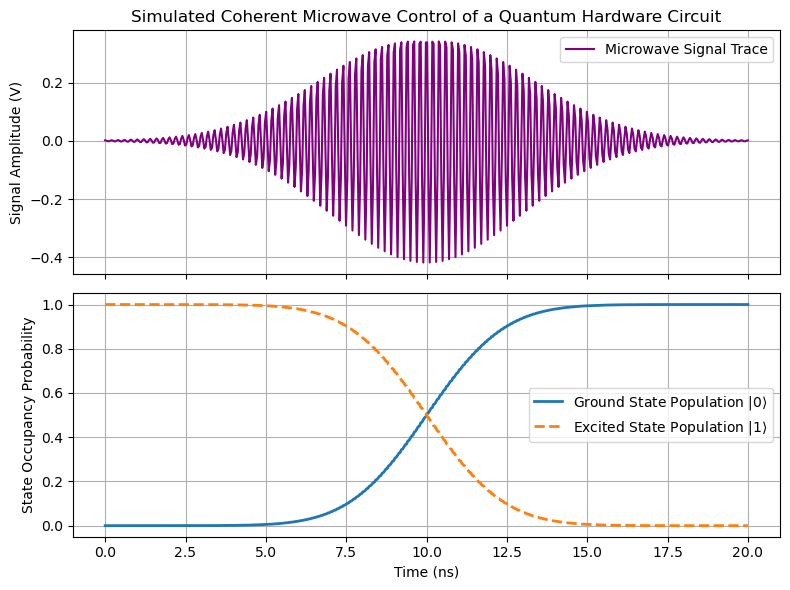

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# =====================================================================
# 1. HARDWARE CONSTANTS & PHYSICS PARAMETERS
# =====================================================================
# We define our system parameters using standard experimental units: 
# Frequencies in GHz and Time in nanoseconds (ns).
f_qubit = 5.0                       # Physical qubit resonance transition frequency (5 GHz)
omega_q = 2 * np.pi * f_qubit       # Convert cyclic frequency (f) to angular frequency (omega)

# =====================================================================
# 2. QUANTUM OPERATORS & SYSTEM HAMILTONIAN CONSTRUCTION
# =====================================================================
# For a 2-level quantum system (qubit), we use standard Hilbert space size N=2.
# qt.destroy(2) creates the 2x2 annihilation (lowering) matrix: [[0, 1], [0, 0]]
b = qt.destroy(2) 

# H0 is the static (drift) Hamiltonian representing the unperturbed qubit energy split.
# Using standard Pauli-Z conventions, the ground and excited states are separated by h-bar * omega.
h0 = -0.5 * omega_q * qt.sigmaz()  

# H1 is the interaction (control) Hamiltonian modeling how the external drive couples to the chip.
# Pauli-X represents charge/voltage coupling, which drives transitions between energy states.
h1 = qt.sigmax()                    

# =====================================================================
# 3. CONTROL SIGNAL ENGINEERING (MICROWAVE PULSE DEFINITION)
# =====================================================================
# Set up the time infrastructure for the numerical ordinary differential equation (ODE) solver.
t_max = 20.0                       # Complete simulation time window in nanoseconds
times = np.linspace(0, t_max, 500) # 500 discrete time-steps to smoothly capture 5 GHz oscillations

# Define the shapes and boundary constraints of our control pulse envelope
pulse_width = 3.0   # The standard deviation (sigma) of our Gaussian envelope in ns
pulse_center = 10.0 # The temporal peak position of our control signal (midway through the run)

# CALIBRATION: The integral of the envelope must equal Pi to achieve a 180-degree state flip.
# For a Gaussian envelope, the analytical area requires an amplitude = Pi / (sigma * sqrt(2*Pi))
drive_amplitude = np.pi / (pulse_width * np.sqrt(2 * np.pi))

def microwave_pulse(t, args):
    """
    Time-dependent callback function passed directly to the QuTiP ODE solver.
    Calculates the exact voltage amplitude of the microwave signal at any time 't'.
    """
    # Calculate the localized amplitude envelope at time 't'
    envelope = drive_amplitude * np.exp(-((t - pulse_center)**2) / (2 * pulse_width**2))
    # Multiply by the high-frequency alternating current (AC) carrier signal
    carrier = np.cos(omega_q * t)
    return envelope * carrier

# Assemble the time-dependent Hamiltonian array using QuTiP's list format.
# Total H(t) = H0 + H1 * microwave_pulse(t)
H = [h0, [h1, microwave_pulse]]

# =====================================================================
# 4. INITIAL CONSTRAINTS & NUMERICAL ODE SOLVER EXPORT
# =====================================================================
# Establish the initial condition: the system begins completely relaxed in the ground state.
# qt.basis(2, 0) outputs the column vector representing state |0>: [[1], [0]]
initial_state = qt.basis(2, 0)  

# Define an observable measurement operator to track over time.
# In a 2-level matrix system, the excited state projection matrix is defined as: (Sigma_Z + Identity) / 2
excited_state_op = (qt.sigmaz() + 1) / 2

# Execute the Master Equation Solver (mesolve).
# Arguments passed: Hamiltonian (H), Initial state vector, time array, collapse/noise channels (empty []), 
# and a list of operators we want to compute expectation values for at each time-step.
result = qt.mesolve(H, initial_state, times, [], [excited_state_op])

# Extract numerical results from the solver object
excited_population = result.expect[0]        # Probability of being in state |1> over time
ground_population = 1.0 - excited_population  # Total probability must equal 1.0 (unitary evolution)

# =====================================================================
# 5. DATA VISUALIZATION AND GRAPH RENDERING
# =====================================================================
# Initialize a stacked 2-panel plot sharing a single X-axis (Time) for clear engineering analysis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Top Plot: Render the physical microwave signal trace showing the fast AC carrier oscillations
pulse_voltages = [microwave_pulse(t, None) for t in times]
ax1.plot(times, pulse_voltages, color='purple', label='Microwave Signal Trace')
ax1.set_ylabel('Signal Amplitude (V)')
ax1.set_title('Simulated Coherent Microwave Control of a Quantum Hardware Circuit')
ax1.legend()
ax1.grid(True)

# Bottom Plot: Render the corresponding quantum state populations shifting over time
ax2.plot(times, ground_population, label=r'Ground State Population $\vert0\rangle$', linewidth=2)
ax2.plot(times, excited_population, label=r'Excited State Population $\vert1\rangle$', linewidth=2, linestyle='--')
ax2.set_xlabel('Time (ns)')
ax2.set_ylabel('State Occupancy Probability')
ax2.legend()
ax2.grid(True)

# Optimize spatial layout margins and render to screen
plt.tight_layout()
plt.show()


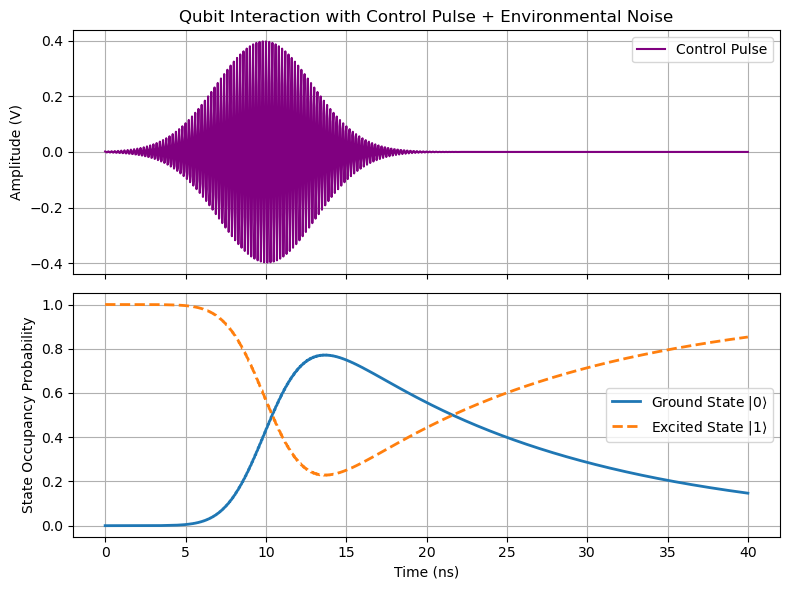

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# =====================================================================
# 1. HARDWARE CONSTANTS & PHYSICS PARAMETERS
# =====================================================================
f_qubit = 5.0                       # Qubit frequency (5 GHz)
omega_q = 2 * np.pi * f_qubit       # Angular frequency

# Simulate a lossy qubit with a short T1 lifetime to visually capture decay
T1_time = 15.0                      # Qubit lifetime in nanoseconds
relaxation_rate = 1.0 / T1_time     # Gamma = 1/T1

# =====================================================================
# 2. QUANTUM OPERATORS & HAMILTONIAN
# =====================================================================
b = qt.destroy(2)                   # Annihilation operator
h0 = -0.5 * omega_q * qt.sigmaz()   # Static qubit energy split
h1 = qt.sigmax()                    # Microwave interaction operator

# =====================================================================
# 3. CONTROL SIGNAL ENGINEERING (MICROWAVE PULSE)
# =====================================================================
t_max = 40.0                        # Extended to 40 ns to watch spontaneous decay
times = np.linspace(0, t_max, 1000)

pulse_width = 3.0   
pulse_center = 10.0 
drive_amplitude = np.pi / (pulse_width * np.sqrt(2 * np.pi))

def microwave_pulse(t, args):
    envelope = drive_amplitude * np.exp(-((t - pulse_center)**2) / (2 * pulse_width**2))
    return envelope * np.cos(omega_q * t)

H = [h0, [h1, microwave_pulse]]

# =====================================================================
# 4. NOISE MODELING (LINDBLAD COLLAPSE OPERATORS)
# =====================================================================
# Lindblad operator for down-conversion: sqrt(Gamma) * b
collapse_operators = [np.sqrt(relaxation_rate) * b]

# =====================================================================
# 5. RUN NUMERICAL MASTER EQUATION SOLVER
# =====================================================================
initial_state = qt.basis(2, 0)      # Start in ground state |0>
excited_state_op = (qt.sigmaz() + 1) / 2

# Execute solver
result = qt.mesolve(H, initial_state, times, collapse_operators, [excited_state_op])

# FIX: Explicitly extract the 0th element from the expectation value list
excited_population = np.array(result.expect[0])
ground_population = 1.0 - excited_population

# =====================================================================
# 6. VISUALIZE RESIDUAL LOSS
# =====================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Top Plot: The Microwave Pulse
ax1.plot(times, [microwave_pulse(t, None) for t in times], color='purple', label='Control Pulse')
ax1.set_ylabel('Amplitude (V)')
ax1.set_title('Qubit Interaction with Control Pulse + Environmental Noise')
ax1.legend()
ax1.grid(True)

# Bottom Plot: State Populations showing decay
ax2.plot(times, ground_population, label=r'Ground State $\vert0\rangle$', linewidth=2)
ax2.plot(times, excited_population, label=r'Excited State $\vert1\rangle$', linewidth=2, linestyle='--')
ax2.set_xlabel('Time (ns)')
ax2.set_ylabel('State Occupancy Probability')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()
